# RQ3 Analysis: BERTScore (Semantic Similarity)

Compares the semantic similarity of human-written vs. LLM-generated PR descriptions using BERTScore.

- Uses the `bert-score` Python package with the `microsoft/deberta-xlarge-mnli` model.
- `rescale_with_baseline=True` for normalized 0.0–1.0 scores.
- Uses `BERTScorer` to cache the model in memory for efficient batch processing.
- Focus on the **F1-Score** as the primary similarity measure.
- Each AI-generated text is compared against its **paired human text** (same `pr_id`).

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, kruskal
import scikit_posthocs as sp
import torch
from bert_score import BERTScorer

In [17]:
# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Data Loading & Preparation

In [18]:
csv_path = '../datasets/temperature_1/run_3/detection_results.csv'
df = pd.read_csv(csv_path)

In [19]:
variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',      # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}
df['Context_Name'] = df['variation'].map(variation_map)
df['normalized_pr_id'] = df['pr_id'].astype(str)

In [20]:
# FILTERING: Keep only paired PRs
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())
valid_ids = ai_pr_ids.intersection(human_pr_ids)

In [21]:
# Human subset
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['model'] = 'Human'

In [22]:
# AI subset
ai_df = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

In [23]:
print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_df['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_df)}")

Paired PR Count: 308
Models found: ['meta-llama/llama-3.1-70b-instruct' 'gpt-5-mini-2025-08-07'
 'Qwen/Qwen2.5-72B-Instruct']
Human entries: 308, AI entries: 5528


## 2. Compute BERTScore

For each AI-generated text, we compare it against its paired human-written text (same `pr_id`) using BERTScore F1.
We use `BERTScorer` with model caching for efficient batch processing of N≈5,526 comparisons.

In [24]:
# Build a lookup: pr_id -> human text
human_text_lookup = dict(zip(human_df['normalized_pr_id'], human_df['text'].astype(str)))

In [25]:
# Prepare reference and candidate lists for BERTScore batch computation
candidates = []  # AI-generated texts
references = []  # Corresponding human texts

for _, row in ai_df.iterrows():
    ai_text = str(row['text']) if pd.notna(row['text']) else ''
    human_text = human_text_lookup.get(row['normalized_pr_id'], '')
    candidates.append(ai_text)
    references.append(human_text)

print(f"Total comparisons to compute: {len(candidates)}")

Total comparisons to compute: 5528


In [26]:
import os
from transformers import AutoTokenizer

# Allow MPS to use more memory (prevents hard cap OOM for large models)
os.environ['PYTORCH_MPS_HIGH_WATERMARK_RATIO'] = '0.0'

# Detect best available device (MPS for Apple Silicon, CUDA for NVIDIA, CPU fallback)
if torch.backends.mps.is_available():
    device = 'mps'
elif torch.cuda.is_available():
    device = 'cuda'
else:
    device = 'cpu'
print(f"Using device: {device}")

# Initialize BERTScorer with model caching, explicit device, and batch size
# NOTE: DeBERTa-xlarge (~3GB) needs small batch_size on MPS to avoid OOM
BATCH_SIZE = 8
MODEL_NAME = 'microsoft/deberta-xlarge-mnli'
scorer = BERTScorer(
    model_type=MODEL_NAME,
    rescale_with_baseline=True,
    lang='en',
    device=device,
    batch_size=BATCH_SIZE
)

# Fix tokenizer max length overflow bug in some fast tokenizers (very large sentinel values)
# This prevents: OverflowError: int too big to convert
SAFE_MAX_LENGTH = 512
tokenizer_max_len = getattr(scorer._tokenizer, 'model_max_length', SAFE_MAX_LENGTH)
if tokenizer_max_len is None or tokenizer_max_len > 1000000:
    scorer._tokenizer.model_max_length = SAFE_MAX_LENGTH
else:
    scorer._tokenizer.model_max_length = min(int(tokenizer_max_len), SAFE_MAX_LENGTH)

print(
    f"BERTScorer initialized successfully "
    f"(device={device}, batch_size={BATCH_SIZE}, tokenizer_max_length={scorer._tokenizer.model_max_length})."
)

Using device: cuda


Loading weights:   0%|          | 0/772 [00:00<?, ?it/s]

DebertaModel LOAD REPORT from: microsoft/deberta-xlarge-mnli
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.bias     | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 
classifier.weight   | UNEXPECTED |  | 
pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERTScorer initialized successfully (device=cuda, batch_size=8, tokenizer_max_length=512).


In [27]:
# Compute BERTScore in chunks with gradient tracking disabled
# Small chunks to avoid MPS/GPU memory exhaustion with large models
CHUNK_SIZE = 128
all_f1_scores = []
total = len(candidates)

print(f"Processing {total} comparisons in chunks of {CHUNK_SIZE} (batch_size={BATCH_SIZE})...")

with torch.no_grad():
    for start_idx in range(0, total, CHUNK_SIZE):
        end_idx = min(start_idx + CHUNK_SIZE, total)
        chunk_cands = candidates[start_idx:end_idx]
        chunk_refs = references[start_idx:end_idx]

        try:
            P, R, F1 = scorer.score(chunk_cands, chunk_refs)
        except OverflowError:
            # Defensive fallback for tokenizer max_length overflow in fast tokenizers
            scorer._tokenizer.model_max_length = 512
            P, R, F1 = scorer.score(chunk_cands, chunk_refs)

        all_f1_scores.extend(F1.cpu().numpy().tolist())

        # Free MPS/CUDA memory between chunks
        if device == 'mps':
            torch.mps.empty_cache()
        elif device == 'cuda':
            torch.cuda.empty_cache()

        print(f"  Processed {end_idx}/{total} ({end_idx*100//total}%)")

# Store F1 scores in the AI dataframe
ai_df['bertscore_f1'] = all_f1_scores

print(f"\nBERTScore computation complete.")
print(f"F1 score range: [{ai_df['bertscore_f1'].min():.4f}, {ai_df['bertscore_f1'].max():.4f}]")
print(f"Mean F1: {ai_df['bertscore_f1'].mean():.4f}")

Processing 5528 comparisons in chunks of 128 (batch_size=8)...
  Processed 128/5528 (2%)
  Processed 256/5528 (4%)
  Processed 384/5528 (6%)
  Processed 512/5528 (9%)
  Processed 640/5528 (11%)
  Processed 768/5528 (13%)
  Processed 896/5528 (16%)
  Processed 1024/5528 (18%)
  Processed 1152/5528 (20%)
  Processed 1280/5528 (23%)
  Processed 1408/5528 (25%)
  Processed 1536/5528 (27%)
  Processed 1664/5528 (30%)
  Processed 1792/5528 (32%)
  Processed 1920/5528 (34%)
  Processed 2048/5528 (37%)
  Processed 2176/5528 (39%)
  Processed 2304/5528 (41%)
  Processed 2432/5528 (43%)
  Processed 2560/5528 (46%)
  Processed 2688/5528 (48%)
  Processed 2816/5528 (50%)
  Processed 2944/5528 (53%)
  Processed 3072/5528 (55%)
  Processed 3200/5528 (57%)
  Processed 3328/5528 (60%)
  Processed 3456/5528 (62%)
  Processed 3584/5528 (64%)
  Processed 3712/5528 (67%)
  Processed 3840/5528 (69%)
  Processed 3968/5528 (71%)
  Processed 4096/5528 (74%)
  Processed 4224/5528 (76%)
  Processed 4352/5528 (7

In [28]:
print("BERTScore F1 metrics computed.")
print(f"AI dataset size with BERTScore: {len(ai_df)}")
display(ai_df[['entry_type', 'model', 'normalized_pr_id', 'bertscore_f1']].head(10))

BERTScore F1 metrics computed.
AI dataset size with BERTScore: 5528


,entry_type,model,normalized_pr_id,bertscore_f1
0,ai,meta-llama/llama-3.1-70b-instruct,PR_kwDOAQ0TF84_uoj2,0.180983
1,ai,gpt-5-mini-2025-08-07,MDExOlB1bGxSZXF1ZXN0MTU3MzkxNDE4,-0.050953
2,ai,gpt-5-mini-2025-08-07,MDExOlB1bGxSZXF1ZXN0NDA2MDA0NDE4,0.025230
3,ai,gpt-5-mini-2025-08-07,MDExOlB1bGxSZXF1ZXN0MzUxNDc4NDg5,0.327554
4,ai,Qwen/Qwen2.5-72B-Instruct,MDExOlB1bGxSZXF1ZXN0NzMyMDE4MTA=,0.108948
5,ai,meta-llama/llama-3.1-70b-instruct,MDExOlB1bGxSZXF1ZXN0MTAzMDAzMjc1,-0.129923
6,ai,meta-llama/llama-3.1-70b-instruct,MDExOlB1bGxSZXF1ZXN0MTM5NTI1MzU0,0.032567
7,ai,gpt-5-mini-2025-08-07,PR_kwDOAQ0TF84shSgK,0.013080
8,ai,Qwen/Qwen2.5-72B-Instruct,MDExOlB1bGxSZXF1ZXN0OTI1NzIwMDE=,0.128804
9,ai,Qwen/Qwen2.5-72B-Instruct,MDExOlB1bGxSZXF1ZXN0NDIzMzE4MDk5,-0.083443


In [56]:
# Truncation diagnostics for Threats to Validity (BERTScore input length limit)
max_len = int(getattr(scorer._tokenizer, 'model_max_length', 512))
tok = scorer._tokenizer

def token_len(text: str) -> int:
    text = '' if pd.isna(text) else str(text)
    return len(tok.encode(text, add_special_tokens=True, truncation=False))

diag_df = ai_df[['normalized_pr_id', 'model', 'Context_Name', 'text']].copy()
diag_df = diag_df.rename(columns={'text': 'ai_text'})
diag_df['human_text'] = diag_df['normalized_pr_id'].map(human_text_lookup).fillna('')

diag_df['ai_tokens'] = diag_df['ai_text'].map(token_len)
diag_df['human_tokens'] = diag_df['human_text'].map(token_len)

diag_df['ai_truncated'] = diag_df['ai_tokens'] > max_len
diag_df['human_truncated'] = diag_df['human_tokens'] > max_len
diag_df['pair_any_truncated'] = diag_df['ai_truncated'] | diag_df['human_truncated']

# How much was truncated (tokens beyond model max length)
diag_df['ai_excess_tokens'] = (diag_df['ai_tokens'] - max_len).clip(lower=0)
diag_df['human_excess_tokens'] = (diag_df['human_tokens'] - max_len).clip(lower=0)
diag_df['pair_excess_tokens'] = diag_df['ai_excess_tokens'] + diag_df['human_excess_tokens']

# Token totals (for proportional loss estimates)
diag_df['ai_total_tokens'] = diag_df['ai_tokens']
diag_df['human_total_tokens'] = diag_df['human_tokens']
diag_df['pair_total_tokens'] = diag_df['ai_tokens'] + diag_df['human_tokens']

trunc_summary = (
    diag_df.groupby(['model', 'Context_Name'], as_index=False)
    .agg(
        N=('normalized_pr_id', 'size'),
        AI_truncated_n=('ai_truncated', 'sum'),
        Human_truncated_n=('human_truncated', 'sum'),
        Pair_any_truncated_n=('pair_any_truncated', 'sum'),
        AI_excess_total_tokens=('ai_excess_tokens', 'sum'),
        Human_excess_total_tokens=('human_excess_tokens', 'sum'),
        Pair_excess_total_tokens=('pair_excess_tokens', 'sum'),
        AI_total_tokens=('ai_total_tokens', 'sum'),
        Human_total_tokens=('human_total_tokens', 'sum'),
        Pair_total_tokens=('pair_total_tokens', 'sum')
    )
)

trunc_summary['AI_trunc_rate_%'] = (100 * trunc_summary['AI_truncated_n'] / trunc_summary['N']).round(2)
trunc_summary['Human_trunc_rate_%'] = (100 * trunc_summary['Human_truncated_n'] / trunc_summary['N']).round(2)
trunc_summary['Pair_any_trunc_rate_%'] = (100 * trunc_summary['Pair_any_truncated_n'] / trunc_summary['N']).round(2)

# Mean excess tokens among truncated items only
trunc_summary['AI_excess_mean_tokens_if_truncated'] = np.where(
    trunc_summary['AI_truncated_n'] > 0,
    (trunc_summary['AI_excess_total_tokens'] / trunc_summary['AI_truncated_n']).round(2),
    0.0
)
trunc_summary['Human_excess_mean_tokens_if_truncated'] = np.where(
    trunc_summary['Human_truncated_n'] > 0,
    (trunc_summary['Human_excess_total_tokens'] / trunc_summary['Human_truncated_n']).round(2),
    0.0
)

# Proportion of tokens removed (excess / total)
trunc_summary['AI_token_loss_%'] = np.where(
    trunc_summary['AI_total_tokens'] > 0,
    (100 * trunc_summary['AI_excess_total_tokens'] / trunc_summary['AI_total_tokens']).round(2),
    0.0
)
trunc_summary['Human_token_loss_%'] = np.where(
    trunc_summary['Human_total_tokens'] > 0,
    (100 * trunc_summary['Human_excess_total_tokens'] / trunc_summary['Human_total_tokens']).round(2),
    0.0
)
trunc_summary['Pair_token_loss_%'] = np.where(
    trunc_summary['Pair_total_tokens'] > 0,
    (100 * trunc_summary['Pair_excess_total_tokens'] / trunc_summary['Pair_total_tokens']).round(2),
    0.0
)

trunc_summary = trunc_summary.sort_values(['model', 'Context_Name']).reset_index(drop=True)

display_cols = [
    'model', 'Context_Name', 'N',
    'AI_trunc_rate_%', 'Human_trunc_rate_%', 'Pair_any_trunc_rate_%',
    'AI_excess_total_tokens', 'Human_excess_total_tokens', 'Pair_excess_total_tokens',
    'AI_excess_mean_tokens_if_truncated', 'Human_excess_mean_tokens_if_truncated',
    'AI_token_loss_%', 'Human_token_loss_%', 'Pair_token_loss_%'
 ]
display(trunc_summary[display_cols])

# Overall detail
overall_n = len(diag_df)
overall_ai_rate = 100 * diag_df['ai_truncated'].mean()
overall_human_rate = 100 * diag_df['human_truncated'].mean()
overall_pair_rate = 100 * diag_df['pair_any_truncated'].mean()

overall_ai_excess = int(diag_df['ai_excess_tokens'].sum())
overall_human_excess = int(diag_df['human_excess_tokens'].sum())
overall_pair_excess = int(diag_df['pair_excess_tokens'].sum())

overall_ai_loss_pct = 100 * diag_df['ai_excess_tokens'].sum() / max(diag_df['ai_tokens'].sum(), 1)
overall_human_loss_pct = 100 * diag_df['human_excess_tokens'].sum() / max(diag_df['human_tokens'].sum(), 1)
overall_pair_loss_pct = 100 * diag_df['pair_excess_tokens'].sum() / max((diag_df['ai_tokens'] + diag_df['human_tokens']).sum(), 1)

max_pair_row = trunc_summary.loc[trunc_summary['Pair_any_trunc_rate_%'].idxmax()]
max_excess_row = trunc_summary.loc[trunc_summary['Pair_excess_total_tokens'].idxmax()]

validity_note = (
    f"Threats to validity — BERTScore truncation: We computed BERTScore using "
    f"{getattr(scorer, 'model_type', 'microsoft/deberta-xlarge-mnli')} with a tokenizer limit of {max_len} tokens. "
    f"Texts longer than this limit were truncated before scoring. Across N={overall_n} AI–human pairs, "
    f"truncation affected {overall_pair_rate:.2f}% of pairs (AI side: {overall_ai_rate:.2f}%, "
    f"human side: {overall_human_rate:.2f}%). In total, truncation removed {overall_pair_excess:,} tokens "
    f"from pair inputs ({overall_pair_loss_pct:.2f}% token loss; AI={overall_ai_excess:,}/{overall_ai_loss_pct:.2f}%, "
    f"Human={overall_human_excess:,}/{overall_human_loss_pct:.2f}%). The highest pair-level truncation rate was "
    f"{max_pair_row['Pair_any_trunc_rate_%']:.2f}% for model={max_pair_row['model']} under context="
    f"{max_pair_row['Context_Name']}, while the largest token removal volume was "
    f"{int(max_excess_row['Pair_excess_total_tokens']):,} tokens for model={max_excess_row['model']} under context="
    f"{max_excess_row['Context_Name']}. Therefore, BERTScore values for long descriptions may under-represent "
    f"content appearing beyond the first {max_len} tokens."
 )

print('\nReady-to-paste validity note:\n')
print(validity_note)

# Optional export for manuscript artifacts
import os
os.makedirs('outputs', exist_ok=True)
trunc_summary.to_csv('outputs/rq3_bertscore_truncation_summary.csv', index=False)
with open('outputs/rq3_bertscore_validity_note.txt', 'w', encoding='utf-8') as f:
    f.write(validity_note + '\n')
print("\nSaved: outputs/rq3_bertscore_truncation_summary.csv")
print("Saved: outputs/rq3_bertscore_validity_note.txt")

,model,Context_Name,N,AI_trunc_rate_%,Human_trunc_rate_%,Pair_any_trunc_rate_%,AI_excess_total_tokens,Human_excess_total_tokens,Pair_excess_total_tokens,AI_excess_mean_tokens_if_truncated,Human_excess_mean_tokens_if_truncated,AI_token_loss_%,Human_token_loss_%,Pair_token_loss_%
0,Qwen/Qwen2.5-72B-Instruct,File Contents,302,0.33,5.30,5.63,1365,1594,2959,1365.00,99.62,3.34,2.14,2.56
1,Qwen/Qwen2.5-72B-Instruct,File Diff,308,0.00,5.19,5.19,0,1594,1594,0.00,99.62,0.00,2.12,1.48
2,Qwen/Qwen2.5-72B-Instruct,Linked Issue,308,0.00,5.19,5.19,0,1594,1594,0.00,99.62,0.00,2.12,1.49
3,Qwen/Qwen2.5-72B-Instruct,PR Title,308,0.00,5.19,5.19,0,1594,1594,0.00,99.62,0.00,2.12,1.75
4,Qwen/Qwen2.5-72B-Instruct,Repo Path,308,0.00,5.19,5.19,0,1594,1594,0.00,99.62,0.00,2.12,1.58
5,Qwen/Qwen2.5-72B-Instruct,Without File Contents,308,0.00,5.19,5.19,0,1594,1594,0.00,99.62,0.00,2.12,1.38
6,gpt-5-mini-2025-08-07,File Contents,302,23.51,5.30,26.82,10459,1594,12053,147.31,99.62,8.94,2.14,6.29
7,gpt-5-mini-2025-08-07,File Diff,308,12.01,5.19,16.56,4931,1594,6525,133.27,99.62,5.32,2.12,3.89
8,gpt-5-mini-2025-08-07,Linked Issue,308,0.00,5.19,5.19,0,1594,1594,0.00,99.62,0.00,2.12,1.10
9,gpt-5-mini-2025-08-07,PR Title,308,3.25,5.19,8.44,524,1594,2118,52.40,99.62,0.59,2.12,1.29



Ready-to-paste validity note:

Threats to validity — BERTScore truncation: We computed BERTScore using microsoft/deberta-xlarge-mnli with a tokenizer limit of 512 tokens. Texts longer than this limit were truncated before scoring. Across N=5528 AI–human pairs, truncation affected 8.54% of pairs (AI side: 3.60%, human side: 5.21%). In total, truncation removed 57,966 tokens from pair inputs (2.61% token loss; AI=29,274/3.38%, Human=28,692/2.12%). The highest pair-level truncation rate was 26.82% for model=gpt-5-mini-2025-08-07 under context=File Contents, while the largest token removal volume was 12,053 tokens for model=gpt-5-mini-2025-08-07 under context=File Contents. Therefore, BERTScore values for long descriptions may under-represent content appearing beyond the first 512 tokens.

Saved: outputs/rq3_bertscore_truncation_summary.csv
Saved: outputs/rq3_bertscore_validity_note.txt


## 3. BERTScore F1 Boxplots by Context per LLM

This mirrors the plotting design used in the BM25 and ROUGE notebooks:

- One panel per LLM model (stacked vertically).
- Each panel includes the 6 AI context boxplots.
- No Human boxplot is included in this view.

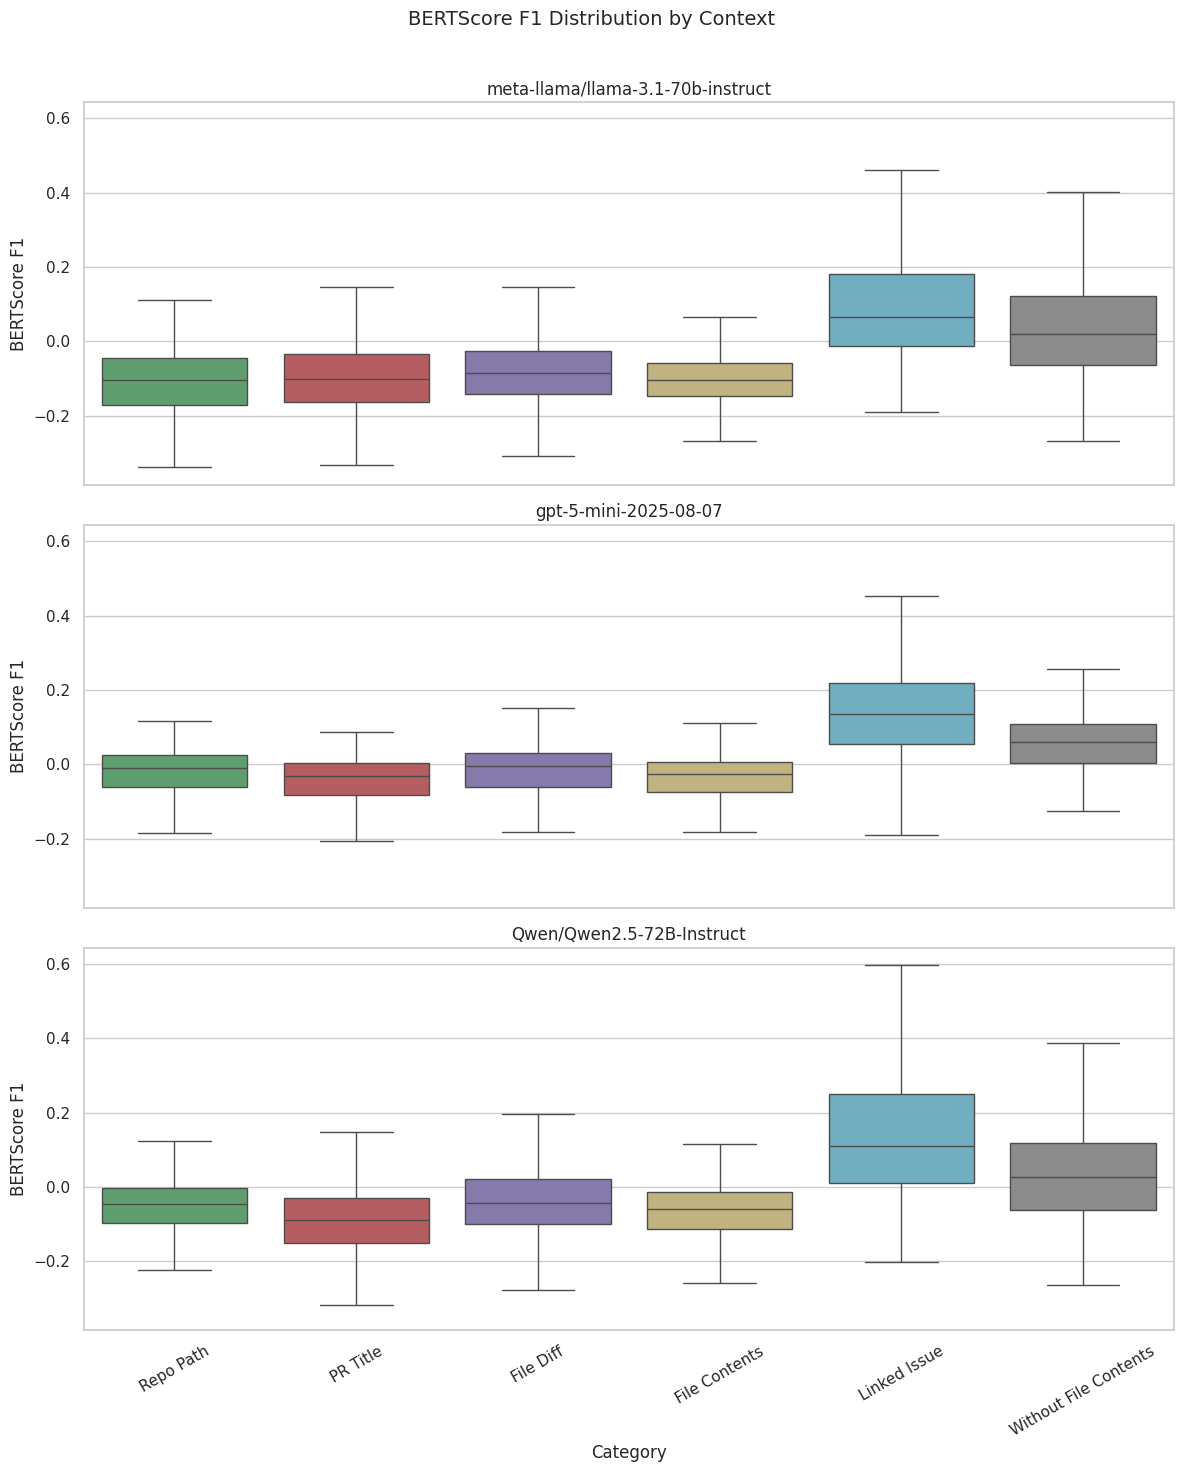

In [29]:
context_order = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']
llm_models = ai_df['model'].dropna().unique().tolist()
x_order = context_order
palette_map = {
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
fig.suptitle('BERTScore F1 Distribution by Context', fontsize=14)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]

    panel_df = ai_df[ai_df['model'] == model][['bertscore_f1', 'Context_Name']].dropna().copy()
    panel_df['Category'] = panel_df['Context_Name']

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='bertscore_f1',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_title(model)
    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '')
    ax.set_ylabel('BERTScore F1')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## 3. Final RQ3 Answer: Human Baseline Comparison

This section directly answers the core RQ3 objective using paired AI↔Human BERTScore results.

- **Reference**: Original human-written PR descriptions (`n=308`, paired PR set).
- **Candidates**: AI descriptions for each model and context (P-1 ... P-6).
- **Reported**: Mean/Median F1 per [Model, Context], Cliff's δ vs Human Baseline (reported but non-discriminative here), and ranking by highest AI Median F1.

In [55]:
# Local helpers (kept here so final section is self-contained after cleanup)
def cliffs_delta(lst1, lst2):
    m, n = len(lst1), len(lst2)
    if m == 0 or n == 0:
        return 0.0
    dom = 0
    for x in lst1:
        for y in lst2:
            if x > y:
                dom += 1
            elif x < y:
                dom -= 1
    return dom / (m * n)

def interpret_cliffs_delta(d):
    d = abs(d)
    if d < 0.147:
        return "Negligible"
    elif d < 0.33:
        return "Small"
    elif d < 0.474:
        return "Medium"
    else:
        return "Large"

variation_names = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']

# Compute Human Ground Truth baseline distribution (n=308 paired PR set)
human_baseline_df = human_df[['normalized_pr_id', 'text']].copy()
human_baseline_df['text'] = human_baseline_df['text'].fillna('').astype(str)
human_baseline_df = human_baseline_df.sort_values('normalized_pr_id').drop_duplicates('normalized_pr_id')

human_candidates = human_baseline_df['text'].tolist()
human_references = human_baseline_df['text'].tolist()
human_total = len(human_candidates)

print(f"Computing human baseline BERTScore F1 for n={human_total}...")

human_f1_scores = []
with torch.no_grad():
    for start_idx in range(0, human_total, CHUNK_SIZE):
        end_idx = min(start_idx + CHUNK_SIZE, human_total)
        chunk_cands = human_candidates[start_idx:end_idx]
        chunk_refs = human_references[start_idx:end_idx]

        _, _, F1_h = scorer.score(chunk_cands, chunk_refs)
        human_f1_scores.extend(F1_h.cpu().numpy().tolist())

        if device == 'mps':
            torch.mps.empty_cache()
        elif device == 'cuda':
            torch.cuda.empty_cache()

human_baseline_df['human_baseline_f1'] = human_f1_scores
human_baseline_vals = human_baseline_df['human_baseline_f1'].values

print(f"Human baseline n = {len(human_baseline_vals)}")
print(f"Human baseline mean F1 = {np.mean(human_baseline_vals):.4f}")
print(f"Human baseline median F1 = {np.median(human_baseline_vals):.4f}")

# Compare every [Model, Context] AI distribution vs Human baseline distribution
human_cmp_rows = []
for model in sorted(ai_df['model'].unique()):
    for ctx in variation_names:
        ai_vals = ai_df[
            (ai_df['model'] == model) & (ai_df['Context_Name'] == ctx)
        ]['bertscore_f1'].dropna().values

        if len(ai_vals) == 0:
            continue

        delta_vs_human = cliffs_delta(ai_vals.tolist(), human_baseline_vals.tolist())
        effect_vs_human = interpret_cliffs_delta(delta_vs_human)

        human_cmp_rows.append({
            'Model': model,
            'Context': ctx,
            'N_AI': len(ai_vals),
            'N_Human': len(human_baseline_vals),
            'AI Mean F1': round(float(np.mean(ai_vals)), 4),
            'AI Median F1': round(float(np.median(ai_vals)), 4),
            'Human Mean F1': round(float(np.mean(human_baseline_vals)), 4),
            'Human Median F1': round(float(np.median(human_baseline_vals)), 4),
            "Cliff's Delta (AI vs Human)": round(float(delta_vs_human), 4),
            'Effect Size': effect_vs_human
        })

human_cmp_df = pd.DataFrame(human_cmp_rows)
human_cmp_df = human_cmp_df.sort_values(['Model', 'AI Median F1', 'AI Mean F1'], ascending=[True, False, False])
human_cmp_df['Most Human Rank (within model)'] = human_cmp_df.groupby('Model')['AI Median F1'].rank(method='dense', ascending=False).astype(int)

print('\n[Model, Context] vs Human baseline (sorted by highest AI Median F1):')
display(human_cmp_df)

# Compact table: best (most-human) context per model by median F1
best_context_per_model_df = (
    human_cmp_df.sort_values(['Model', 'AI Median F1', 'AI Mean F1'], ascending=[True, False, False])
    .groupby('Model', as_index=False)
    .first()[['Model', 'Context', 'AI Mean F1', 'AI Median F1', "Cliff's Delta (AI vs Human)", 'Effect Size', 'Most Human Rank (within model)']]
    .sort_values('Model')
)

print('\nBest context per model (highest AI Median F1):')
display(best_context_per_model_df)

# Save outputs
import os
os.makedirs('outputs', exist_ok=True)
human_cmp_df.to_csv('outputs/rq3_bertscore_ai_vs_human_baseline.csv', index=False)
best_context_per_model_df.to_csv('outputs/rq3_bertscore_most_human_context_per_model.csv', index=False)
print('Saved: outputs/rq3_bertscore_ai_vs_human_baseline.csv')
print('Saved: outputs/rq3_bertscore_most_human_context_per_model.csv')

Computing human baseline BERTScore F1 for n=308...
Human baseline n = 308
Human baseline mean F1 = 1.0000
Human baseline median F1 = 1.0000

[Model, Context] vs Human baseline (sorted by highest AI Median F1):


,Model,Context,N_AI,N_Human,AI Mean F1,AI Median F1,Human Mean F1,Human Median F1,Cliff's Delta (AI vs Human),Effect Size,Most Human Rank (within model)
4,Qwen/Qwen2.5-72B-Instruct,Linked Issue,308,308,0.1440,0.1098,1.0,1.0,-1.0,Large,1
5,Qwen/Qwen2.5-72B-Instruct,Without File Contents,308,308,0.0546,0.0265,1.0,1.0,-1.0,Large,2
2,Qwen/Qwen2.5-72B-Instruct,File Diff,308,308,-0.0393,-0.0418,1.0,1.0,-1.0,Large,3
0,Qwen/Qwen2.5-72B-Instruct,Repo Path,308,308,-0.0522,-0.0450,1.0,1.0,-1.0,Large,4
3,Qwen/Qwen2.5-72B-Instruct,File Contents,302,308,-0.0690,-0.0597,1.0,1.0,-1.0,Large,5
1,Qwen/Qwen2.5-72B-Instruct,PR Title,308,308,-0.0855,-0.0883,1.0,1.0,-1.0,Large,6
10,gpt-5-mini-2025-08-07,Linked Issue,308,308,0.1404,0.1364,1.0,1.0,-1.0,Large,1
11,gpt-5-mini-2025-08-07,Without File Contents,308,308,0.0467,0.0586,1.0,1.0,-1.0,Large,2
8,gpt-5-mini-2025-08-07,File Diff,308,308,-0.0239,-0.0058,1.0,1.0,-1.0,Large,3
6,gpt-5-mini-2025-08-07,Repo Path,308,308,-0.0362,-0.0112,1.0,1.0,-1.0,Large,4



Best context per model (highest AI Median F1):


,Model,Context,AI Mean F1,AI Median F1,Cliff's Delta (AI vs Human),Effect Size,Most Human Rank (within model)
0,Qwen/Qwen2.5-72B-Instruct,Linked Issue,0.1440,0.1098,-1.0,Large,1
1,gpt-5-mini-2025-08-07,Linked Issue,0.1404,0.1364,-1.0,Large,1
2,meta-llama/llama-3.1-70b-instruct,Linked Issue,0.0998,0.0665,-1.0,Large,1


Saved: outputs/rq3_bertscore_ai_vs_human_baseline.csv
Saved: outputs/rq3_bertscore_most_human_context_per_model.csv
